In [3]:
import requests
import re
from bs4 import BeautifulSoup
import xml.etree.ElementTree as ET
import pandas as pd
import time
import json
import pandas as pd
from google import genai
from google.genai import types
import time
from sentence_transformers import SentenceTransformer
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.documents import Document
import chromadb
import json
import networkx as nx
import matplotlib.pyplot as plt
from neo4j import GraphDatabase
import os

c:\Users\huawei\Documents\Programmieren\SocialMediaAnalytics\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### 1. Collecting all the episodes of season 1 & 2

In [ ]:
def find_episodes_in_season(Season):
    url = f"https://prettylittleliars.fandom.com/api.php?action=parse&page=Season_{Season}&format=xml"
    response = requests.get(url)
    root = ET.fromstring(response.text)
    parse = root.find("parse")
    text_elem = parse.find("text")
    html = text_elem.text
    soup = BeautifulSoup(html, "html.parser")
    hrefs = []
    for a in soup.find_all("a", href=True):
        # check if the parent is a <b> tag
        if a.find_parent("b"):
            hrefs.append(a["href"].replace("/wiki/", ""))
    return hrefs


As the table of episodes does not use ids or classes and contains multiple links (for example for character descriptions), the only way to distinguish a link for an episode was to find out if it was Bold, therefore I had to check the parent tag.

In [371]:
episodes = []
for s in range(2):
    episodes_curr_season = find_episodes_in_season(s+1)
    episodes.append(episodes_curr_season)

### 2. Scraping all of the individual summaries

In [ ]:
def parse_summary(page):
    url = f"https://prettylittleliars.fandom.com/api.php?action=parse&page={page}&format=xml"
    print(url)
    response = requests.get(url)
    root = ET.fromstring(response.text)
    parse = root.find("parse")
    text_elem = parse.find("text")
    html = text_elem.text
    soup = BeautifulSoup(html, "html.parser")

    try: 
        h2_first = soup.find(id="Synopsis")
        h2_last = soup.find(id="Title")

        ps_between = []
        for node in h2_first.parent.next_siblings:
            if getattr(node, "name", None) is None:
                continue
            if node is h2_last or (hasattr(node, "name") and node.name == "h2" and node == h2_last):
                break
            if node.name == "p":
                ps_between.append(node)
    except AttributeError:
        h2_first = soup.find(id="Plot")
        h2_last = soup.find(id="Title")

        ps_between = []
        for node in h2_first.parent.next_siblings:
            if getattr(node, "name", None) is None:
                continue
            if node is h2_last or (hasattr(node, "name") and node.name == "h2" and node == h2_last):
                break
            # Only appending <p> tags to skip images
            if node.name == "p":
                ps_between.append(node)

    ps_between_texts = [p.get_text(" ", strip=True) for p in ps_between]
    # removing /n from the text for easier readability
    final_string = re.sub(r"/n", "", " ".join(ps_between_texts), flags=re.DOTALL | re.MULTILINE)
    return final_string

Once again the page barely uses any ids or classes or wrapper tags. Therefore I had to instead find the two headlines at the beginning and end of a summary and select all the &lt;p> Tags in between, skipping any unwanted images etc. Unfortunately the structure was not very coherent, sometimes the summary was titled "Synopsis", sometimes "Plot" which I had to solve by using a try-except function. 

In [379]:
episodes_dicts = []
for season_num, season_episodes in enumerate(episodes):
    for i, episode in enumerate(season_episodes):
        d = {"title": episode.replace("_", " ").replace("%27", "'"), "summary": parse_summary(episode), "season": season_num + 1, "episode_number": i+1}
        episodes_dicts.append(d)
        time.sleep(3)
df = pd.DataFrame(episodes_dicts)

https://prettylittleliars.fandom.com/api.php?action=parse&page=Pilot&format=xml
https://prettylittleliars.fandom.com/api.php?action=parse&page=The_Jenna_Thing&format=xml
https://prettylittleliars.fandom.com/api.php?action=parse&page=To_Kill_a_Mocking_Girl&format=xml
https://prettylittleliars.fandom.com/api.php?action=parse&page=Can_You_Hear_Me_Now%3F&format=xml
https://prettylittleliars.fandom.com/api.php?action=parse&page=Reality_Bites_Me&format=xml
https://prettylittleliars.fandom.com/api.php?action=parse&page=There%27s_No_Place_Like_Homecoming&format=xml
https://prettylittleliars.fandom.com/api.php?action=parse&page=The_Homecoming_Hangover&format=xml
https://prettylittleliars.fandom.com/api.php?action=parse&page=Please,_Do_Talk_About_Me_When_I%27m_Gone&format=xml
https://prettylittleliars.fandom.com/api.php?action=parse&page=The_Perfect_Storm&format=xml
https://prettylittleliars.fandom.com/api.php?action=parse&page=Keep_Your_Friends_Close&format=xml
https://prettylittleliars.fandom.

### 3. The scraped data

In [380]:
df = pd.DataFrame(episodes_dicts)
df

,title,summary,season,episode_number
0,Pilot,"When their best friend mysteriously vanishes, ...",1,1
1,The Jenna Thing,"The Liars sit in the Apple Rose Grille, a rest...",1,2
2,To Kill a Mocking Girl,The girls feel an uneasy obligation set by the...,1,3
3,Can You Hear Me Now%3F,"After wrecking Sean's car, Hanna gets lectured...",1,4
4,Reality Bites Me,"At the Hastings house , the girls are discussi...",1,5
5,There's No Place Like Homecoming,"Hanna , Spencer , and Emily arrive at Aria's t...",1,6
6,The Homecoming Hangover,"At the homecoming dance, Spencer , Aria , and ...",1,7
7,"Please, Do Talk About Me When I'm Gone","Aria , Spencer , Emily , and Hanna begin to pr...",1,8
8,The Perfect Storm,There was a storm brewing in Rosewood last nig...,1,9
9,Keep Your Friends Close,"At school , Mona delivers invitations for her ...",1,10


In [381]:
df.to_csv('PrettyLittleLiars_Episodes.csv', index=False)

### 4. Extract entities and relationships

In [ ]:
client = genai.Client(api_key="MY_API_KEY")

In [ ]:
prompt = """
            You are an entity-relationship extractor.
            Extract ONLY explicitly mentioned entities in the text and their relationships with one another.

            Rules:
            Extract ONLY explicitly mentioned entities and relationships.
            Entities can ONLY be Groups or Characters.
            Each entity has FIELDS: name, aliases, description (not empty).
            Each relationship has FIELDS: source, target, type, evidence (not empty).
            Descriptions MUST be at least one sentence → summarize from the text.
            Evidence MUST directly quote text passages (max. 150 characters).
            Evidence is the decisive text snippet that supports the relationship.
            If "A" is mentioned, always extract A under the name "A".
            If the interaction is neutral, minimal, or ambiguous, do NOT extract a relationship at all.
            Only choose between the given relationship types.

            Relationship types: ENGAGED | FRIEND | FAMILY | SIBLING | STEP-SIBLING | PARENT | CHILD | DATED | MARRIED | BLACKMAILED | ALLIED

            Output as JSON, no explanation:
            {
            "entities": [{ "type": "Character", "name": "...", "aliases": [], "description": "..." }, ...],
            "relationships": [{ "source": "...", "target": "...", "type": "...", "evidence": "..." }, ...]
            }
           
        """

Originally I tried to use local LLMS through Ollama, but not only did that take up a significant amount of times, the LLMs were also ususally too small to properly follow the rules and understanding the concepts of relatinships, so I had to use AIStudio instead.

In [ ]:
for index, episode in df.iterrows():
    print(episode["title"])
    print(episode["summary"])
    response = client.models.generate_content(
        model="gemini-3.1-flash-lite",
        #model="gemma-4-26b-a4b-it",
        contents=f"""{prompt}

                Extract from the following passage:

                {episode["summary"]}
                """,
        config=types.GenerateContentConfig(
            temperature=0.1,
            response_mime_type="application/json",
        ),
)
    print(response.text)

    json_file = json.loads(response.text)
    for entity in json_file["relationships"]:
        entity["season"]=episode["season"]
        entity["episode"]=episode["episode_number"]

    rel_path = "relationships.json"
    with open(rel_path, "a", encoding="utf-8") as f:
        json.dump(json_file["relationships"], f, ensure_ascii=False, indent=2)

    char_path = "entities.json"
    with open(char_path, "a", encoding="utf-8") as f:
        json.dump(json_file["entities"], f, ensure_ascii=False, indent=2)
    time.sleep(7)
        


Save the Date
Aria and Hanna talk with Spencer in her car, while she fills them in on how she got away from Garrett in his cop car. Emily joins them, when suddenly the man of the hour parks in front of Jenna's House , which is across the street from his parents' house. He could go either way, but he goes to Jenna's house. Toby is out on an errand picking up his parents from the airport. The girls trod closer to take a better look when the light flicks on, revealing Jenna, who slowly strips to reveal the same black negligee the girls saw her trying on in the store! Garrett approaches her, starts to caress her shoulders, then starts kissing her slowly; Jenna kisses him back.  The next morning, Hanna enters the kitchen to find Emily doing crunches. They both reveal they haven't slept since seeing what they saw. Emily then joins Hanna for breakfast, not in the best of moods. Her muscles are still sore, so she asks Hanna to pass her the medical cream she bought the day before. Apparently, s

In [ ]:
for path in ["relationships.json", "entities.json"]:
    with open(path, "r", encoding="utf-8") as f:
        content = f.read()
    
    fixed = content.replace("][", ",")
    
    with open(path, "w", encoding="utf-8") as f:
        f.write(fixed)

### 5. Cleaning the extracted entities and relationships

This function normalizes the names of entities and relationships, as some Characters have different names in the books and series, different arrays are needed for each.

In [ ]:
aliases_book = {
    "Ali": "Alison DiLaurentis",
    "Alison": "Alison DiLaurentis",
    "Ezra": "Ezra Fitz",
    "Mr. Fitz": "Ezra Fitz",
    "Hanna": "Hanna Marin",
    "Emily": "Emily Fields",
    "Aria": "Aria Montgomery",
    "Spencer": "Spencer Hastings",
    "Maya": "Maya St. Germain",
    "Melissa": "Melissa Hastings",
    "Wren": "Wren Kim",
    "Jessica": "Jessica DiLaurentis",
    "Toby": "Toby Cavanaugh",
    "Jenna": "Jenna Marshall",
    "Wilden": "Darren Wilden",
    "Detective Wilden": "Darren Wilden",
    "Sean": "Sean Ackard",
    "Ben": "Ben Coogan",
    "Mona": "Mona Vanderwaal",
    "Meredith": "Meredith Succi",
    "Byron": "Byron Montgomery",
    "Ella": "Ella Montgomery",
    "Veronica": "Veronica Hastings",
    "Isabel": "Isabel Marin",
    "Amber": "Amber Victorino",
    "Peter": "Peter Hastings",
    "Andrew": "Andrew Newhoff",
    "Alex": "Alex Santiago",
    "Lucas": "Lucas Gottesman",
    "Ashley": "Ashley Marin",
    "Mike": "Mike Montgomery",
    "Toby Walker": "Toby Cavanaugh",
    "Toby Marshall": "Toby Cavanaugh",
    "Holden": "Holden Strauss",
    "The girls' clique": "The Liars",
    "The girls": "The Liars",
    "The Clique": "The Liars",
    "Pretty Little Liars": "The Liars",
    "The Liars (again)": "The Liars",
    "The Liars' Clique": "The Liars",
    "Paige": "Paige McCullers",
    "Paige McCullough": "Paige McCullers",
    "Officer Garrett Reynolds": "Garrett Reynolds",
    "Garrett": "Garrett Reynolds",
    "Dr. Anne Sullivan": "Dr. Sullivan",
    "Hanna Marin's father (Tom)": "Tom Marin",
    "the Marins": "The Marin Family",
    "the Fields' family": "The Fields Family",
    "Dr. Amanda Sullivan": "Dr. Sullivan",
    "Hanna Marin's father": "Tom Marin",
    "Holden": "Holden Straussberg",
    "Officer Wilden": "Darren Wilden", 
    "Wren Kingston": "Wren Kim",
    "Rylie": "Riley Wolfe",
    "Riley": "Riley Wolfe",
    "Trista": "Trista Taylor",
    "Ali (Alison)": "Alison DiLaurentis",
    "Ian": "Ian Thomas",
    "Noel": "Noel Kahn",
    "Andrew": "Andrew Campbell",
    "Andrew Newhoff": "Andrew Campbell",

    "FRIEND_OF": "FRIEND",
    "DATER_OF": "DATED",
    "DATING": "DATED",
    "LOVER_OF": "LOVES",
    "BLACKMAILED_BY": "BLACKMAILED",
    
}

aliases_series = {
    "Ali": "Alison DiLaurentis",
    "Alison": "Alison DiLaurentis",
    "Ezra": "Ezra Fitz",
    "Mr. Fitz": "Ezra Fitz",
    "Hanna": "Hanna Marin",
    "Emily": "Emily Fields",
    "Aria": "Aria Montgomery",
    "Spencer": "Spencer Hastings",
    "Maya": "Maya St. Germain",
    "Melissa": "Melissa Hastings",
    "Wren": "Wren Kingston",
    "Jessica": "Jessica DiLaurentis",
    "Toby": "Toby Cavanaugh",
    "Jenna": "Jenna Marshall",
    "Wilden": "Darren Wilden",
    "Detective Wilden": "Darren Wilden",
    "Sean": "Sean Ackard",
    "Ben": "Ben Coogan",
    "Mona": "Mona Vanderwaal",
    "Meredith": "Meredith Succi",
    "Byron": "Byron Montgomery",
    "Ella": "Ella Montgomery",
    "Veronica": "Veronica Hastings",
    "Isabel": "Isabel Marin",
    "Amber": "Amber Victorino",
    "Peter": "Peter Hastings",
    "Andrew": "Andrew Newhoff",
    "Alex": "Alex Santiago",
    "Lucas": "Lucas Gottesman",
    "Ashley": "Ashley Marin",
    "Mike": "Mike Montgomery",
    "Toby Walker": "Toby Cavanaugh",
    "Toby Marshall": "Toby Cavanaugh",
    "Holden": "Holden Strauss",
    "The girls' clique": "The Liars",
    "The girls": "The Liars",
    "The Clique": "The Liars",
    "Pretty Little Liars": "The Liars",
    "The Liars (again)": "The Liars",
    "The Liars' Clique": "The Liars",
    "Paige": "Paige McCullers",
    "Paige McCullough": "Paige McCullers",
    "Officer Garrett Reynolds": "Garrett Reynolds",
    "Garrett": "Garrett Reynolds",
    "Dr. Anne Sullivan": "Dr. Sullivan",
    "Hanna Marin's father (Tom)": "Tom Marin",
    "the Marins": "The Marin Family",
    "the Fields' family": "The Fields Family",
    "Dr. Amanda Sullivan": "Dr. Sullivan",
    "Hanna Marin's father": "Tom Marin",
    "Holden": "Holden Straussberg",
    "Officer Wilden": "Darren Wilden",
    "Officer Darren Wilden": "Darren Wilden",
    "The girls (Aria Montgomery, Spencer Hastings, Hanna Marin, Emily Fields)": "The Liars",
    "Dr. Wren Kingston": "Wren Kingston",
    "Caleb": "Caleb Rivers",
    "Alex Wolf": "Alex Santiago",
    "The Police": "The Rosewood Police Force",
    "Ian": "Ian Thomas",
    "Jackie": "Jackie Molina",
    "Darren": "Darren Wilden",
    "Noel": "Noel Kahn",
    "Andrew": "Andrew Campbell",
    "Andrew Newhoff": "Andrew Campbell",

    "FRIEND_OF": "FRIEND",
    "DATER_OF": "DATED",
    "DATING": "DATED",
    "LOVER_OF": "LOVES",
    "BLACKMAILED_BY": "BLACKMAILED", 
}

def normalize(name, type):
    if type == "book":
        return aliases_book.get(name, name)
    if type == "series":
        return aliases_series.get(name, name)

First the entities are cleaned by 
1. normalizing the names 
2. merging two instances of the same character into one.

In [ ]:
seen = {}

with open("entities.json", "r", encoding="utf-8") as f:
    entities = json.load(f)
    
    for entity in entities:
        entity["name"] = normalize(entity["name"], "series")
        if entity["name"] not in seen:
            seen[entity["name"]] = entity.copy()
            seen[entity["name"]]["description"] = [seen[entity["name"]]["description"]]
        else:
            existing_entity = seen[entity["name"]]
            if entity["description"] not in existing_entity["description"]:
                existing_entity["description"].append(entity["description"])

with open("entities_cleaned.json", "w", encoding="utf-8") as f:
    json.dump(list(seen.values()), f, ensure_ascii=False, indent=2)

Secondly, the entities are cleaned by 
1. normalizing the names
2. merging two instances of the relationship into one as long as there is no different relationship type in between (in case of changing of relationships. For example Spencer and Emily can first be friends, then get into a fight, become enemies and then can go back to friends. In that case you would not want the two instances of them being friends to merge.)

In [ ]:
relationships_cleaned = []
with open("relationships.json", "r", encoding="utf-8") as f:
    book_relationships = json.load(f)
    sources = []
    for rel in book_relationships:
        if rel["source"] not in sources:
            sources.append(rel["source"])

    for source in sources:
        source_relationships = []
        for rel in book_relationships:
            rel["type"] = normalize(rel["type"], "series")
            rel["source"] = normalize(rel["source"], "series")
            rel["target"] = normalize(rel["target"], "series")
            if source == rel["source"]:
                last_rel = None
                last_rel_index = None

                for i in range(len(source_relationships) - 1, -1, -1):
                    if (source_relationships[i]["source"] == rel["source"] and source_relationships[i]["target"] == rel["target"]):
                        last_rel = source_relationships[i]
                        last_rel_index = i
                        break

                if last_rel and (last_rel["source"] == rel["source"] and last_rel["target"] == rel["target"] and last_rel["type"] == rel["type"]):
                    if not isinstance(source_relationships[last_rel_index]["evidence"], list):
                        source_relationships[last_rel_index]["evidence"] = [source_relationships[last_rel_index]["evidence"]]
                    source_relationships[last_rel_index]["evidence"].append(rel["evidence"])
                else:
                    source_relationships.append(rel)

        for s_rel in source_relationships:
            s_rel["source"] = normalize(s_rel["source"], "series")
            s_rel["target"] = normalize(s_rel["target"], "series")
            s_rel["type"] = normalize(s_rel["type"], "series")
            relationships_cleaned.append(s_rel)
    
with open("relationships_cleaned.json", "w", encoding="utf-8") as f:
    json.dump(list(relationships_cleaned), f, ensure_ascii=False, indent=2)

### 6. Visualizing the graph
(This is not really needed, I just thought it would save you the hassle of creating an instance of a neo4j database just to look at the graph)

In [ ]:
G = nx.DiGraph()

In [ ]:
with open("entities_cleaned.json", "r", encoding="utf-8") as f:
    entities = json.load(f)

    for ent in entities:
        if ent["type"] == "Character":
            G.add_node(
                ent["name"],
                entity_type=ent.get("type")
            )

with open("relationships_cleaned.json", "r", encoding="utf-8") as f:
    relationships = json.load(f)

for rel in relationships:
    source = rel["source"]
    target = rel["target"]

    if not G.has_node(source):
        G.add_node(source, entity_type="Character")
    if not G.has_node(target):
        G.add_node(target, entity_type="Character")

    G.add_edge(
        source,
        target,
        relation=rel.get("type")
    )

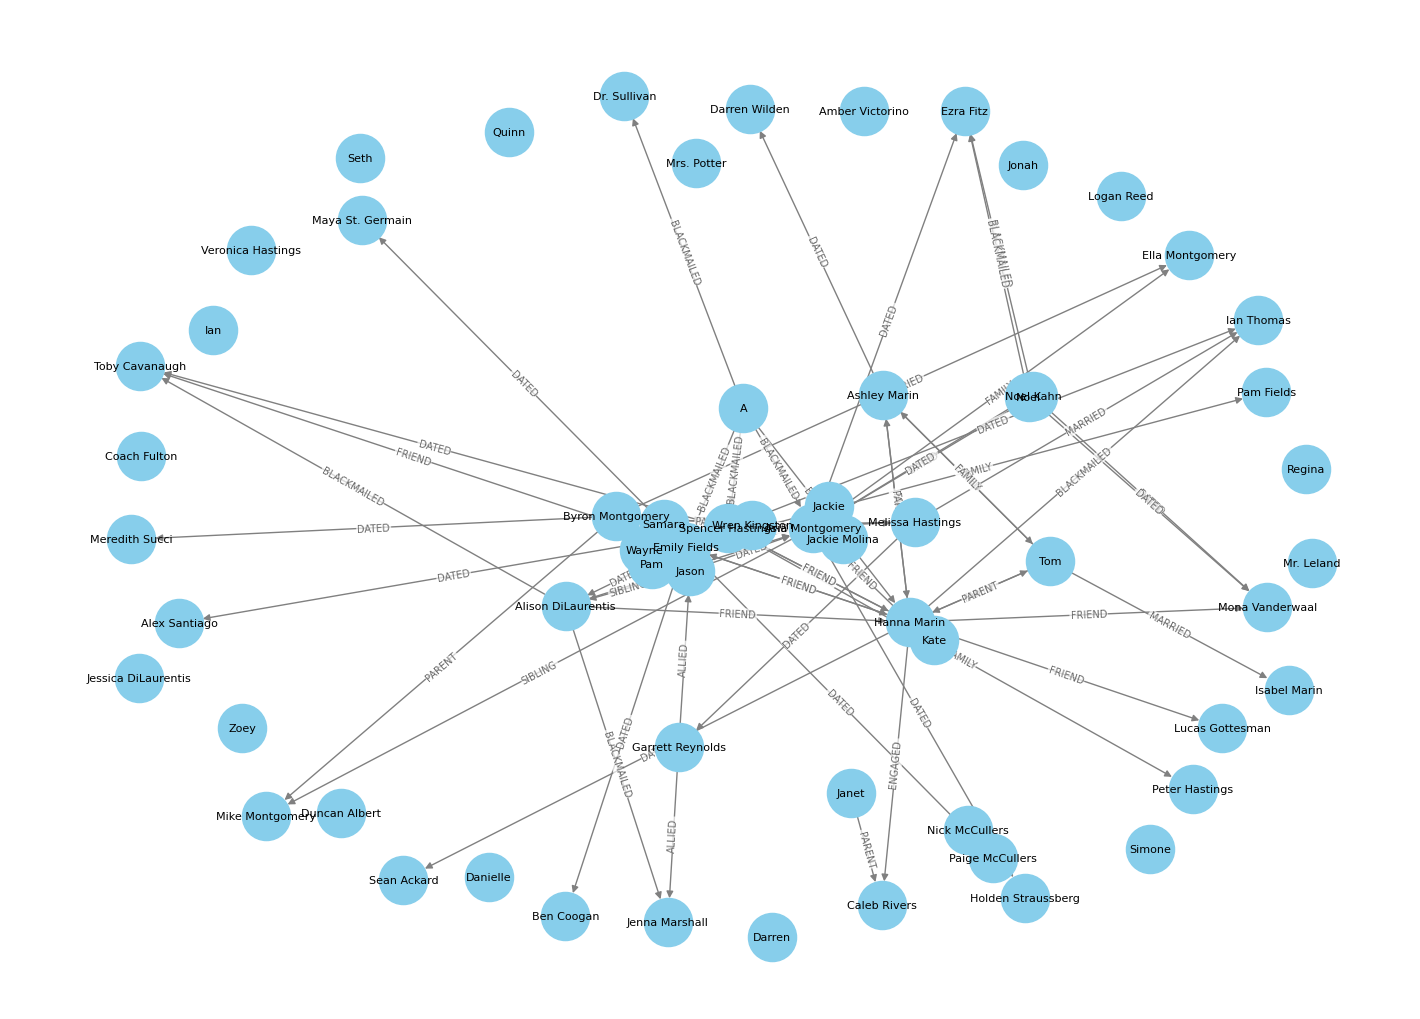

In [ ]:
plt.figure(figsize=(14, 10))
pos = nx.spring_layout(G, seed=22)

nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=1200,
    node_color="skyblue",
    edge_color="gray",
    font_size=8,
    arrows=True
)

# 1) Einfach: Kantenbeschriftungen aus dem Edge-Attribut "type" (oder "label")
edge_labels = {(u, v): d.get("relation", "NO LABEL") or d.get("label", "NO LABEL") for u, v, d in G.edges(data=True)}
nx.draw_networkx_edge_labels(
    G,
    pos,
    edge_labels=edge_labels,
    font_color="dimgray",
    font_size=7,
    rotate=True,
    bbox=dict(boxstyle="round,pad=0.1", fc="white", ec="none", alpha=0.7)
)

plt.axis("off")
plt.show()

As you can see, unfortunately some of the nodes do not have any edges. Further there are some nodes missing, for example most of the parents. I suppose with a better model, more entities and relationships could have been extracted. Also there are significantly more characters than in the book-graph. This is probably due to the fact that the episode summaries are more detailed.

### 7. Adding the entities and relationships to the graph database

In [ ]:
URI = "bolt://localhost:7687"
USER = os.getenv("NEO_USER", "neo4j")
PASSWORD = os.getenv("NEO_PASSWORD", "password")

driver = GraphDatabase.driver(URI, auth=(USER, PASSWORD))

In [ ]:
with open("entities_cleaned.json", "r", encoding="utf-8") as f:
    entities = json.load(f)
    
characters = [e for e in entities if e["type"] == "Character"]
groups = [e for e in entities if e["type"] == "Group"]

query_characters = """
UNWIND $rows AS row
MERGE (c:Character {name: row.name})
SET c.type = row.type,
    c.aliases = coalesce(row.aliases, []),
    c.description = [x IN coalesce(row.description, []) WHERE x IS NOT NULL AND trim(x) <> ""]
"""

query_groups = """
UNWIND $rows AS row
MERGE (g:Group {name: row.name})
SET g.type = row.type,
    g.aliases = coalesce(row.aliases, []),
    g.description = [x IN coalesce(row.description, []) WHERE x IS NOT NULL AND trim(x) <> ""]
"""

with driver.session(database="series") as session:
    if characters:
        session.run(query_characters, rows=characters)
    if groups:
        session.run(query_groups, rows=groups)

driver.close()

In [ ]:
driver = GraphDatabase.driver(URI, auth=(USER, PASSWORD))

with open("relationships_cleaned.json", "r", encoding="utf-8") as f:
    relationships = json.load(f)

query = """
UNWIND $rows AS row
MATCH (source {name: row.source})
MATCH (target {name: row.target})
MERGE (source)-[r:RELATED_TO {
    type: row.type,
    season: row.season,
    episode: row.episode
}]->(target)
SET r.evidence = row.evidence
"""

with driver.session(database="series") as session:
    session.run(query, rows=relationships)

driver.close()

### 8. Creating the Vector Database

In [ ]:
model = SentenceTransformer("microsoft/harrier-oss-v1-270m")
df = pd.read_csv("PrettyLittleLiars_Episodes.csv")

[transformers] Unrecognized keys in `rope_parameters` for 'rope_type'='default': {'sliding_attention', 'full_attention'}
Loading weights: 100%|██████████| 236/236 [00:00<00:00, 4985.80it/s]
[transformers] Unrecognized keys in `rope_parameters` for 'rope_type'='default': {'sliding_attention', 'full_attention'}
[transformers] Unrecognized keys in `rope_parameters` for 'rope_type'='default': {'sliding_attention', 'full_attention'}


In the following example I am using ChromaDB as we had previously used ChromaDB in the Application Project. I do not believe that the choice of vector database is of significance in this application. I am creating a seperate collections for the book vectors and the series vectors.

In [ ]:
client = chromadb.PersistentClient(path="../chroma_db")
collection = client.get_or_create_collection(
    name="series",
    metadata={"hnsw:space": "cosine"})

In [ ]:
documents = []
embeddings = []
metadatas = []
ids = []

for _, episode in df.iterrows():
    print(episode["title"])
    # Splitting the text into chunk
    text_splitter = RecursiveCharacterTextSplitter(chunk_size=512, chunk_overlap=50)
    chunks = text_splitter.split_text(episode["summary"])
    for chunk_idx, chunk in enumerate(chunks):
        chunk_id = f"season_{episode["season"]}_episode_{episode["episode_number"]}_chunk_{chunk_idx}"

        documents.append(chunk)
        # embedding each chunk
        embeddings.append(model.encode(chunk).tolist())
        # adding the relevant metadata
        metadatas.append({
            "title": episode["title"],
            "season_index": episode["season"],
            "episode_index": episode["episode_number"],
            "chunk_index": chunk_idx
        })
        ids.append(chunk_id)

collection.add(
    ids=ids,
    documents=documents,
    embeddings=embeddings,
    metadatas=metadatas
)

Pilot
The Jenna Thing
To Kill a Mocking Girl
Can You Hear Me Now%3F
Reality Bites Me
There's No Place Like Homecoming
The Homecoming Hangover
Please, Do Talk About Me When I'm Gone
The Perfect Storm
Keep Your Friends Close
Moments Later
Salt Meets Wound
Know Your Frenemies
Careful What U Wish 4
If At First You Don't Succeed, Lie, Lie Again
Je Suis une Amie
The New Normal
The Badass Seed
A Person of Interest
Someone to Watch Over Me
Monsters in the End
For Whom the Bell Tolls
It's Alive
The Goodbye Look
My Name Is Trouble
Blind Dates
The Devil You Know
Never Letting Go
Surface Tension
Save the Date
Picture This
Touched by an 'A'-ngel
I Must Confess
Over My Dead Body
The First Secret
Through Many Dangers, Toils, and Snares
A Hot Piece of A
Let the Water Hold Me Down
The Blond Leading the Blind
A Kiss Before Lying
The Naked Truth
CTRL: A
Breaking the Code
Father Knows Best
Eye of the Beholder
If These Dolls Could Talk
UnmAsked
